# 00 · Setup check
Confirms the kernel, `src/` import and data loading work. The first code cell is the standard opening for every notebook in this repo.

In [1]:
%load_ext autoreload
%autoreload 2
import sys
from pathlib import Path

# Make `src` importable: repo root locally, or an uploaded Kaggle dataset containing src/
for p in [Path.cwd(), *Path.cwd().parents, *(f.parent.parent for f in Path("/kaggle/input").glob("**/src/config.py"))]:
    if (p / "src" / "config.py").exists():
        sys.path.insert(0, str(p.resolve()))
        break

from src import config
print("on kaggle:", config.ON_KAGGLE, "| seed:", config.SEED)

on kaggle: False | seed: 42


In [2]:
for task in ["regression", "classification"]:
    train, test, sub = config.load(task)
    print(f"{task:15s} train {train.shape}  test {test.shape}  sample_submission {sub.shape}  <- {config.data_dir(task)}")

regression      train (15589, 12)  test (3898, 11)  sample_submission (3898, 2)  <- C:\D-Drive\IIITB\ML\Project\dataset\regression
classification  train (10000, 22)  test (2500, 21)  sample_submission (2500, 2)  <- C:\D-Drive\IIITB\ML\Project\dataset\classification


pandas 2.3.3 | sklearn 1.9.1


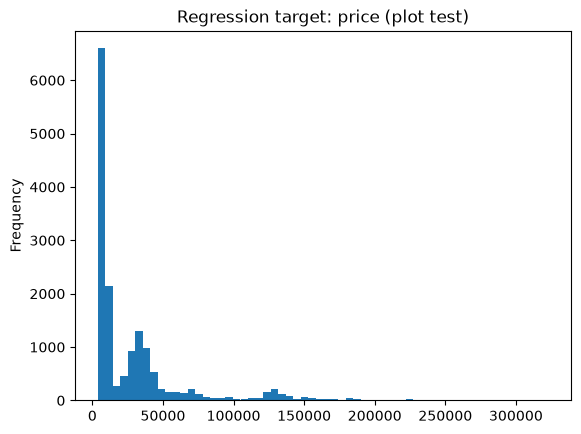

In [3]:
import sklearn, pandas as pd, matplotlib.pyplot as plt
print("pandas", pd.__version__, "| sklearn", sklearn.__version__)
train, _, _ = config.load("regression")
ax = train["price"].plot.hist(bins=60, title="Regression target: price (plot test)")
plt.show()